In [1]:
%pip install pymc

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pymc as pm

print("PyMC instalado correctamente")
print("Versión:", pm.__version__)

g++ not available, if using conda: `conda install gxx`


PyMC instalado correctamente
Versión: 6.3.2


In [3]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

<h1 style="text-align: center; color: #FFD700;">Modelo SIR con pyMC</h1>

# Formulación del problema

Resolver el ajuste de parámetros del modelo SIR utilizando un enfoque bayesiana y la librería pyMC de Python.

In [4]:
import numpy as np   # Se usa para arreglos numericos
import matplotlib.pyplot as plt   # Se usa para graficar 
import pymc as pm     # Se usa para construir el modelo bayesiano
import arviz as az    # Se usa para la convergencia de las cadenas de Markov
import pytensor.tensor as pt # Proporciona operaciones matemáticas simbólicas que utiliza PyMC

from pytensor.compile.ops import as_op  # Permite incorporar funciones de Python, como la solución numérica del modelo SIR
from scipy.integrate import odeint   # Resuelve numericamente el sistema
from scipy.stats import gaussian_kde, chi2 # proporciona herramientas de la distribución chi-cuadrada
from matplotlib.patches import Ellipse  # Permite dibujar elipses en las gráficas

Se introducen los datos correspondientes al número de individuos infectados durante 15 días consecutivos. La población total considerada es de 763 individuos y se supone una desviación estándar constante de 20 para representar la incertidumbre asociada con las observaciones. Estos datos se utilizarán para estimar los parámetros desconocidos del modelo.
$$I_{\text{datos}} = [1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4]$$

$$t = 0, 1, \dots, 14[cite: 9].$$

In [6]:
# Genera un arreglo de 15 valores 
t_datos = np.arange(15)

# Arreglo que contiene el numero de personas infectadas
I_datos = np.array([
    1, 3, 6, 25, 73,
    222, 294, 258, 237, 191,
    125, 69, 27, 11, 4
])

# Poblacion total
N = 763

# Desviación estandar de 20 afectados 
sigma_datos = np.full(15, 20.0)

Se define el modelo epidemiológico SIR mediante un sistema de tres ecuaciones diferenciales ordinarias, que describen la evolución temporal de las poblaciones susceptible, infectada y recuperada.

$$\frac{dS}{dt} = -aSI$$

$$\frac{dI}{dt} = aSI - bI$$

$$\frac{dR}{dt} = bI$$

Donde $a$ representa el parámetro de transmisión y $b$ el parámetro de recuperación.

Se consideran las condiciones iniciales $S(0) = 762$, $I(0) = 1$ y $R(0) = 0$. 

In [7]:
# Se define el modelo SIR 
def modelo_SIR(y, t, a, b):

    S, I, R = y

    dSdt = -a * S * I
    dIdt = a * S * I - b * I
    dRdt = b * I

    return [dSdt, dIdt, dRdt]

# Se resuelve el sistema
def resolver_SIR(a, b, t):

    return odeint(
        modelo_SIR,
        # Condiciones iniciales
        [762, 1, 0],
        t,
        args=(a, b),
        rtol=1e-6,
        atol=1e-8
    )

Se establece una función chi-cuadrada para cuantificar las diferencias entre los valores de infectados observados y los calculados mediante el modelo SIR. Esta función permite evaluar qué tan bien determinados valores de los parámetros reproducen los datos experimentales.

$$\chi^2(a, b) = \sum_{i=1}^{15} \frac{(I_i^{\text{obs}} - I_i^{\text{modelo}})^2}{\sigma_i^2}$$

Cuanto menor sea el valor de esta función, mejor será el ajuste, considerando la incertidumbre supuesta.

In [8]:
# Se define la funcion chi cuadrada
def chi_cuadrada(a, b):

    I_modelo = resolver_SIR(
        a, b, t_datos
    )[:, 1]

    # Diferencia entre los datos observados y los valores predichos por el modelo
    residuos = I_datos - I_modelo

    return np.sum(
        (residuos / sigma_datos)**2
    )

Se construye una función que conecta la solución numérica del modelo SIR con el entorno de inferencia bayesiana de PyMC. Para ello se utiliza el decorador as_op de PyTensor, que permite incorporar funciones numéricas externas en un modelo probabilístico.
Esta conexión permite evaluar el número de infectados previsto por el modelo para cada combinación de parámetros propuesta durante el muestreo MCMC.

In [9]:
@as_op(
    itypes=[pt.dscalar, pt.dscalar],   # Esto permite que PyMC evalúe el modelo SIR para diferentes combinaciones de parámetros.
    otypes=[pt.dvector]
)
# Recibe los parametros de transmisión y recuperación
def SIR_pymc(a, b):
    
    # Establece intervalos permitidos para los parametros
    a = float(a)
    b = float(b)

    if not (0.0005 < a < 0.004 and 0.1 < b < 1.0):
        return np.full(
            len(t_datos), 1e10, dtype=np.float64
        )
    # Solucion del modelo 
    try:
        I_modelo = resolver_SIR(
            a, b, t_datos
        )[:, 1]

        # Verifica que son numeros finitos 
        if not np.all(np.isfinite(I_modelo)):
            raise ValueError("Predicción no finita")

        return np.asarray(
            I_modelo,
            dtype=np.float64
        )

    except (RuntimeError, ValueError, FloatingPointError):
        return np.full(
            len(t_datos), 1e10, dtype=np.float64
        )

Se consideran cuatro cadenas de Markov con condiciones iniciales diferentes, con la finalidad de explorar la distribución posterior. Para cada cadena se generan 3000 muestras posteriores y se emplean 1500 iteraciones iniciales de adaptación que serán descartadas. 

In [10]:
# Genera numero aleatorios 
rng = np.random.default_rng(42)

n = 3000 # Numero de interaciones 
burn_in = 1500  # numero de interaciones aleatorias

# Se establecen cuatro pares de valores iniciales para comenzar las cadenas de Markov.
iniciales = [
    (0.0017, 0.35),
    (0.0020, 0.42),
    (0.0023, 0.51),
    (0.0025, 0.56)
]

valores_iniciales = [
    {"a": a0, "b": b0}
    for a0, b0 in iniciales
]

# Tamaño de los pasos de las cadenas 
paso_a = 0.000055
paso_b = 0.018

Se utiliza el algoritmo Metropolis-Hastings para generar cuatro cadenas de Markov que aproximan la distribución posterior conjunta de los parámetros.

In [11]:
# Crea un modelo probabilistico utilizando la biblioteca PyMC
with pm.Model() as modelo_bayesiano:

    # S establecen distribuciones de probabilidad uniformes para los parametros
    a = pm.Uniform(
        "a", lower=0.0005, upper=0.004,
        transform=None
    )

    b = pm.Uniform(
        "b", lower=0.1, upper=1.0,
        transform=None
    )
    
    # Calculo de los infectados predichos 
    I_pred = SIR_pymc(a, b)

    # Establece el ajuste bayesiano
    pm.Normal(
        "infectados",
        mu=I_pred,
        sigma=sigma_datos,
        observed=I_datos
    )

    # Se calcula el estadistico chi cuadrada para cada combinacion de parametros 
    pm.Deterministic(
        "chi2",
        pt.sum(
            ((I_datos - I_pred) / sigma_datos)**2
        )
    )

    # se establece el algoritmo metropolis
    paso = pm.Metropolis(
        vars=[a, b],
        S=np.array([paso_a, paso_b]),
        blocked=True
    )

    # Ejecuta las cuatro cadenas de Markov
    muestras_pymc = pm.sample(
        draws=n,
        tune=burn_in,
        chains=4,
        cores=1,
        step=paso,
        initvals=valores_iniciales,
        random_seed=42,
        progressbar=True,
        return_inferencedata=True,
        discard_tuned_samples=True
    )

Sequential sampling (4 chains in 1 job)
Metropolis: [a, b]


Output()

Sampling 4 chains for 1_500 tune and 3_000 draw iterations (6_000 + 12_000 draws total) took 58 seconds.


Una vez completada la simulación, se recuperan las muestras de ambos parámetros generadas por las cuatro cadenas de Markov.

In [12]:
# Extraen los parametros a y b alamacenados en muestras del ajuste bayesiano
cadenas_a = muestras_pymc.posterior["a"].values
cadenas_b = muestras_pymc.posterior["b"].values

# Combinan las muestras de ambos parametros en un unico arreglo
cadenas = np.stack(
    [cadenas_a, cadenas_b],
    axis=-1
)

posteriores = cadenas

# Transforma el arreglo tridimensional en una matriz de dos columnas 
muestras = posteriores.reshape(-1, 2)

a_muestras = muestras[:, 0]
b_muestras = muestras[:, 1]

A partir de las muestras posteriores se calculan las medias de los parámetros \(a\) y \(b\), así como sus intervalos creíbles del 95 %.
También se identifica la combinación de parámetros que presenta el menor valor de chi-cuadrada entre las muestras generadas.

In [13]:
# Calcula el promedio de las muestras posteriores de los parametrps a y b
media_a, media_b = np.mean(
    muestras, axis=0
)

# Calcula los cuantiles cprrespondientes
limites = np.quantile(
    muestras,
    [0.025, 0.975],
    axis=0
)

# Recupera los valores estadistico chi cuadrada 
chi_muestras = (
    muestras_pymc.posterior["chi2"]
    .values.reshape(-1)
)

# Identifica la combinacion de parametros que produce el menor valor de chi-cuadrada
indice_mejor = np.argmin(chi_muestras)

# Recupera los valores de a y b correspondientes a esa posicion
mejor_a, mejor_b = muestras[indice_mejor]
chi_min = chi_muestras[indice_mejor]

print("=== RESULTADOS BAYESIANOS ===")

print(f"Media posterior a = {media_a:.8f}")
print(f"Media posterior b = {media_b:.6f}")

print(f"Mejor a encontrado = {mejor_a:.8f}")
print(f"Mejor b encontrado = {mejor_b:.6f}")

print(f"Chi cuadrada = {chi_min:.4f}")

print("Intervalo creible 95% a =", limites[:, 0])
print("Intervalo creible 95% b =", limites[:, 1])

print(az.summary(
    muestras_pymc,
    var_names=["a", "b"],
    round_to=6
))

=== RESULTADOS BAYESIANOS ===
Media posterior a = 0.00218323
Media posterior b = 0.446914
Mejor a encontrado = 0.00218036
Mejor b encontrado = 0.445431
Chi cuadrada = 11.2681
Intervalo creible 95% a = [0.00211229 0.00225258]
Intervalo creible 95% b = [0.41511098 0.48018114]
       mean        sd  eti89_lb  eti89_ub     ess_bulk     ess_tail     r_hat  \
a  0.002183  0.000035  0.002127  0.002241  2020.975526  2264.642750  1.001684   
b  0.446914  0.016501  0.420603  0.473339  2007.542518  2569.860114  1.001729   

   mcse_mean   mcse_sd  
a   0.000001  0.000001  
b   0.000369  0.000234  


**Parámetro de transmisión $a = 0.00218323$**

Este valor representa el coeficiente de transmisión de la enfermedad. Determina la rapidez con la que los individuos susceptibles pasan al grupo de infectados mediante el término $aSI$. Cuanto mayor sea $a$, más rápido se pueden producir los contagios.

**Parámetro de recuperación $b = 0.446914$**

Este valor representa la tasa de recuperación de los individuos infectados, expresada en días inversos si el tiempo está medido en días.

Podemos estimar la duración media del periodo infeccioso como:

$$\frac{1}{b} = \frac{1}{0.446914} \approx 2.24 \text{ días}$$

El tiempo medio que permanece infectada una persona es aproximadamente de $2.24$ días.

Se obtuvo:

$$\chi_{\text{mín}}^2 = 11.2681$$

Este valor representa la menor discrepancia encontrada entre los datos observados y las predicciones del modelo, teniendo en cuenta la desviación estándar supuesta de 20 infectados.

Se calcula el estadístico Gelman-Rubin, también denominado R, con el propósito de evaluar la convergencia de las cuatro cadenas de Markov.

In [14]:
# Calcula el estadistico para evaluar la convergenncia de las cadenas 
Rhat = az.rhat(
    muestras_pymc,
    var_names=["a", "b"]
)

print("=== GELMAN-RUBIN ===")

print(
    f"Gelman-Rubin a = "
    f"{float(Rhat['a'].values):.4f}"
)

print(
    f"Gelman-Rubin b = "
    f"{float(Rhat['b'].values):.4f}"
)

=== GELMAN-RUBIN ===
Gelman-Rubin a = 1.0017
Gelman-Rubin b = 1.0017


Estos valores se encuentran muy próximos a 1 y son inferiores al criterio de referencia de 1.01, lo que indica que las cuatro cadenas de Markov presentan indicadores favorables de convergencia.

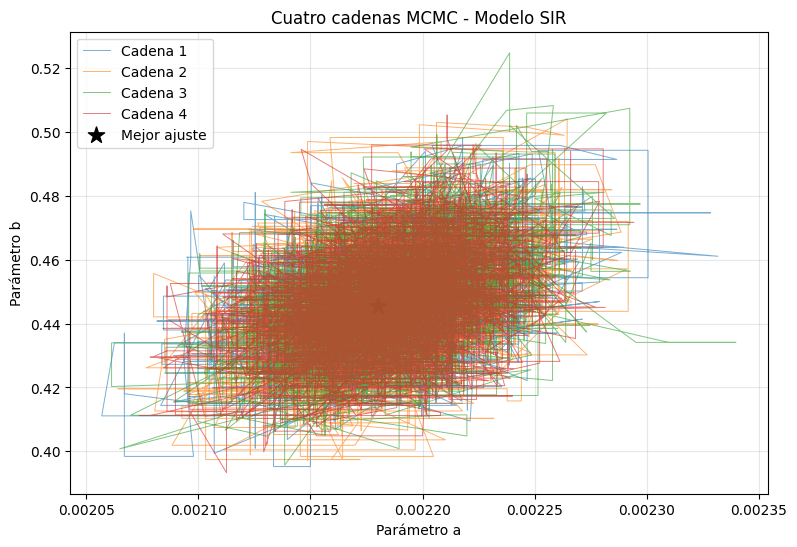

In [15]:
plt.figure(figsize=(9, 6))

for j in range(4):

    plt.plot(
        cadenas[j, :, 0],
        cadenas[j, :, 1],
        linewidth=0.7,
        alpha=0.6,
        label=f"Cadena {j+1}"
    )

plt.scatter(
    mejor_a, mejor_b,
    color="black",
    marker="*",
    s=150,
    label="Mejor ajuste"
)

plt.xlabel("Parámetro a")
plt.ylabel("Parámetro b")
plt.title("Cuatro cadenas MCMC - Modelo SIR")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

La gráfica muestra que las cuatro cadenas exploran regiones semejantes y presentan una concentración alrededor de valores centrales bien definidos.

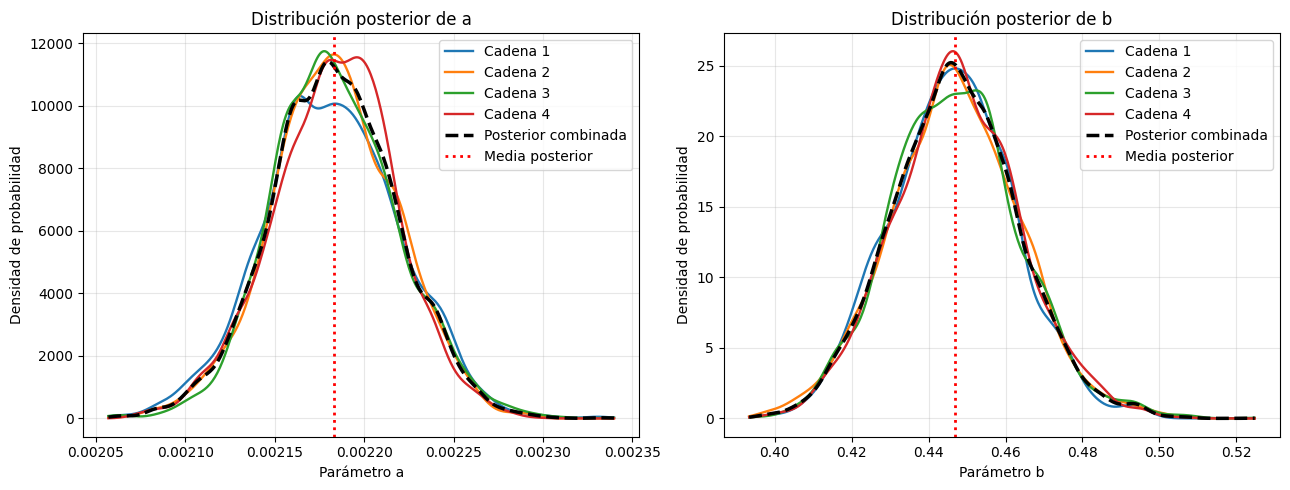

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, parametro, datos in zip(
    axes,
    ["a", "b"],
    [cadenas_a, cadenas_b]
):

    todos = datos.flatten()

    x = np.linspace(
        np.min(todos),
        np.max(todos),
        400
    )

    for j in range(4):

        densidad = gaussian_kde(datos[j])

        ax.plot(
            x,
            densidad(x),
            linewidth=1.7,
            label=f"Cadena {j+1}"
        )

    densidad_total = gaussian_kde(todos)

    ax.plot(
        x,
        densidad_total(x),
        color="black",
        linestyle="--",
        linewidth=2.5,
        label="Posterior combinada"
    )

    ax.axvline(
        np.mean(todos),
        color="red",
        linestyle=":",
        linewidth=2,
        label="Media posterior"
    )

    ax.set_title(
        f"Distribución posterior de {parametro}"
    )

    ax.set_xlabel(f"Parámetro {parametro}")
    ax.set_ylabel("Densidad de probabilidad")

    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

Se construyen las distribuciones posteriores marginales de los parámetros \(a\) y \(b\) utilizando estimación de densidad por kernel gaussiano.
Para cada parámetro se representan cuatro curvas correspondientes a las cadenas de Markov y una quinta curva que combina la información de todas las muestras.

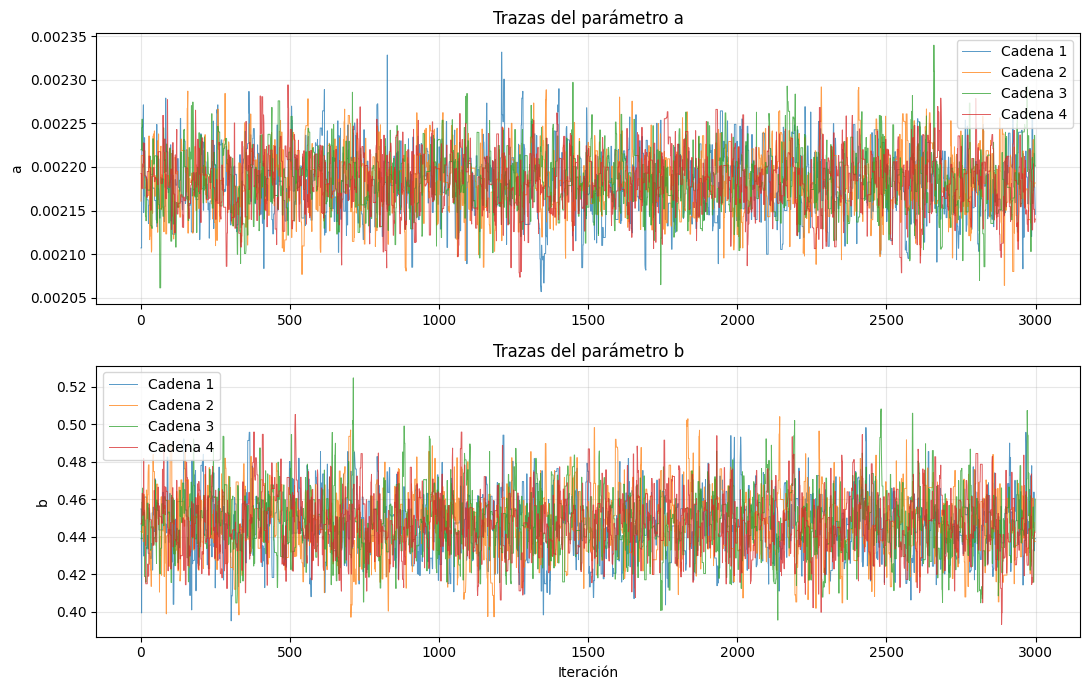

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7))

for j in range(4):

    axes[0].plot(
        cadenas_a[j],
        linewidth=0.7,
        alpha=0.75,
        label=f"Cadena {j+1}"
    )

    axes[1].plot(
        cadenas_b[j],
        linewidth=0.7,
        alpha=0.75,
        label=f"Cadena {j+1}"
    )

axes[0].set_title("Trazas del parámetro a")
axes[0].set_ylabel("a")

axes[1].set_title("Trazas del parámetro b")
axes[1].set_ylabel("b")
axes[1].set_xlabel("Iteración")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

Se construyen las gráficas de trazas de los parámetros \(a\) y \(b\) para observar su evolución a lo largo de las iteraciones del algoritmo MCMC.

Se calcula la matriz de covarianza de los parámetros utilizando las muestras posteriores. Esta matriz describe la dispersión individual de cada parámetro y su relación estadística conjunta.

In [18]:
# Calcula la matriz de covarianza 
cov = np.cov(muestras.T)

print("=== MATRIZ DE COVARIANZA ===")
print(cov)

# Calcula los valores propios y vectores propios de la matriz de covarianza
valores, vectores = np.linalg.eigh(cov)

orden = np.argsort(valores)[::-1]

valores = valores[orden]
vectores = vectores[:, orden]

# calcula el ángulo que forma el vector propio principal con el eje horizontal.
angulo = np.degrees(
    np.arctan2(
        vectores[1, 0],
        vectores[0, 0]
    )
)

=== MATRIZ DE COVARIANZA ===
[[1.25508140e-09 2.18167592e-07]
 [2.18167592e-07 2.72269222e-04]]


Se construyen elipses asociadas con niveles de credibilidad del 68.3 %, 95.4 % y 99.73 % para representar la incertidumbre conjunta de los parámetros estimados.
Las elipses se obtienen a partir de la matriz de covarianza posterior y los cuantiles de la distribución chi-cuadrada con dos grados de libertad.

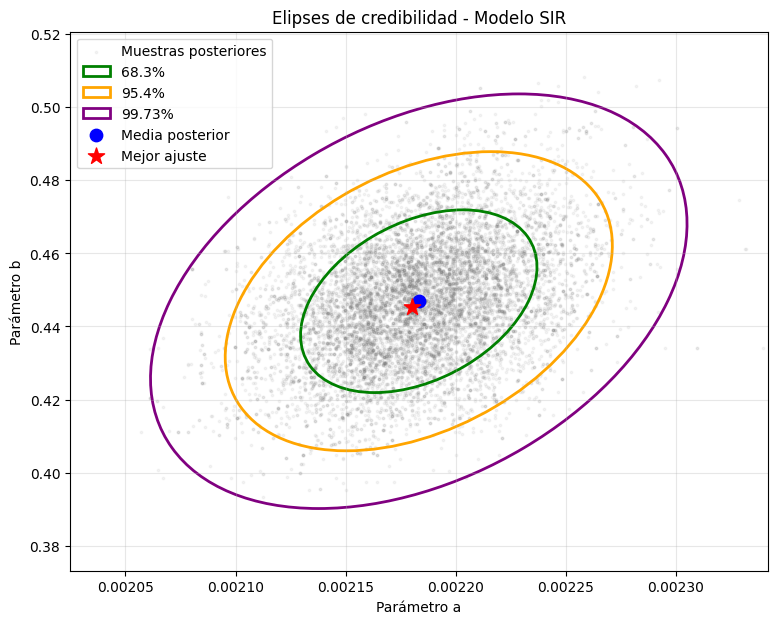

In [19]:
fig, ax = plt.subplots(figsize=(9, 7))

ax.scatter(
    a_muestras, b_muestras,
    s=3, alpha=0.08,
    color="gray",
    label="Muestras posteriores"
)

# Niveles de probabilidad 
niveles = [
    (0.683, "green", "68.3%"),
    (0.954, "orange", "95.4%"),
    (0.9973, "purple", "99.73%")
]

# Construccion de la elipse
for nivel, color, etiqueta in niveles:
    
    # Se usa el factor de chi cuadrda 
    factor = chi2.ppf(nivel, df=2)

    ancho = 2 * np.sqrt(valores[0] * factor)
    alto = 2 * np.sqrt(valores[1] * factor)

    elipse = Ellipse(
        xy=(media_a, media_b),
        width=ancho,
        height=alto,
        angle=angulo,
        facecolor="none",
        edgecolor=color,
        linewidth=2,
        label=etiqueta
    )

    ax.add_patch(elipse)

ax.scatter(
    media_a, media_b,
    color="blue", s=80,
    label="Media posterior"
)

ax.scatter(
    mejor_a, mejor_b,
    color="red",
    marker="*",
    s=150,
    label="Mejor ajuste"
)

fact = np.sqrt(chi2.ppf(0.9973, df=2))
ext = fact * np.sqrt(np.diag(cov))

ax.set_xlim(
    media_a - 1.3*ext[0],
    media_a + 1.3*ext[0]
)

ax.set_ylim(
    media_b - 1.3*ext[1],
    media_b + 1.3*ext[1]
)

ax.set_xlabel("Parámetro a")
ax.set_ylabel("Parámetro b")
ax.set_title("Elipses de credibilidad - Modelo SIR")

ax.legend()
ax.grid(alpha=0.3)
plt.show()

La gráfica representa la incertidumbre conjunta de los parámetros de transmisión (a) y recuperación (b) del modelo SIR.

Las elipses muestran regiones de credibilidad del 68.3 %, 95.4 % y 99.73 %, donde se concentran las posibles combinaciones de ambos parámetros. Su inclinación positiva indica una correlación positiva moderada entre ellos.

Para representar la incertidumbre de las estimaciones se seleccionan aleatoriamente 100 pares de parámetros de la distribución posterior. Para cada combinación se resuelve el sistema SIR y se obtiene una trayectoria de infectados.
A partir de estas trayectorias se construye una banda creíble aproximada del 95 %, que permite visualizar la variabilidad del comportamiento predicho por el modelo como consecuencia de la incertidumbre paramétrica.

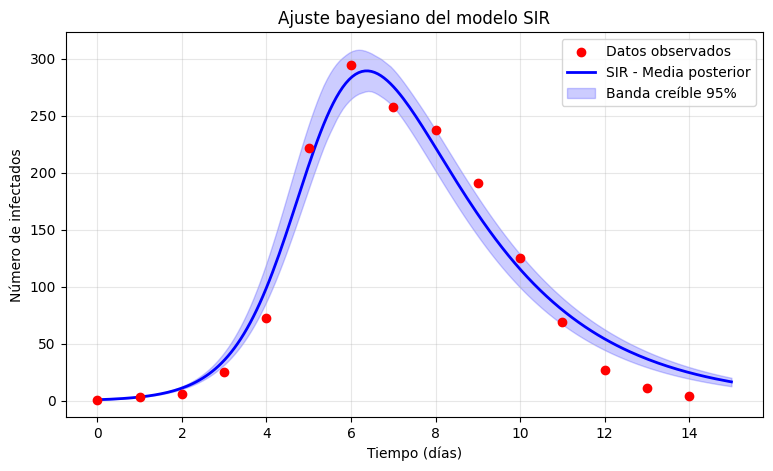

In [21]:
# Se generan 200 puntos entre los dias 0 y 15
t = np.linspace(0, 15, 200)

# Resuelve el modelo SIR utilizando las medidas ibtenidas anteriormente 
I_ajustado = resolver_SIR(
    media_a, media_b, t
)[:, 1]

# Selecciona aleatoriamente 100 combianaciones de los parametros a y b entre las 12,000 muestras 
indices = rng.choice(
    len(muestras),
    size=100,
    replace=False
)

# Para combinacion seleccionada se resuelve nuevamene el modelo SIR
curvas = []

for idx in indices:

    a_sim, b_sim = muestras[idx]

    I_sim = resolver_SIR(
        a_sim, b_sim, t
    )[:, 1]

    curvas.append(I_sim)

curvas = np.array(curvas)

inferior = np.percentile(
    curvas, 2.5, axis=0
)

superior = np.percentile(
    curvas, 97.5, axis=0
)

plt.figure(figsize=(9, 5))

plt.scatter(
    t_datos, I_datos,
    color="red",
    label="Datos observados",
    zorder=3
)

plt.plot(
    t, I_ajustado,
    color="blue",
    linewidth=2,
    label="SIR - Media posterior"
)

plt.fill_between(
    t, inferior, superior,
    color="blue",
    alpha=0.2,
    label="Banda creíble 95%"
)

plt.xlabel("Tiempo (días)")
plt.ylabel("Número de infectados")
plt.title("Ajuste bayesiano del modelo SIR")

plt.grid(alpha=0.3)
plt.legend()
plt.show()

La gráfica muestra la comparación entre los datos observados de infectados y las predicciones del modelo SIR, cuyos parámetros fueron estimados mediante inferencia bayesiana utilizando cuatro cadenas de Markov (MCMC).
Se observa que el modelo reproduce adecuadamente el comportamiento general de la epidemia, caracterizado por un crecimiento inicial de los contagios, un máximo de infectados y una disminución progresiva.

La curva azul sigue de manera cercana la tendencia de los datos observados, especialmente durante el crecimiento inicial y alrededor del máximo de contagios.
Sin embargo, durante los últimos días se observan algunas diferencias, ya que el modelo predice una disminución más lenta que la registrada en los datos.
Por lo tanto, aunque el ajuste general es favorable, existen discrepancias principalmente en la etapa final de la epidemia.